# signaux bruts et réseau cnn 1D

 Dans V1 et V2, je travaille sur les 561 variables calculées à la main. Ici, j'entraîne un réseau convolutif 1D directement sur les **signaux bruts** des capteurs (fenêtres de 128 mesures sur 9 canaux), et je compare le résultat au MLP et à la régression logistique.

**Même protocole que dans V1 et V2.** Je découpe par volontaires entiers, je répète les entraînements sur plusieurs graines (moyenne ± écart-type), j'utilise la validation croisée groupée par volontaires pour fixer le nombre d'époques, et je n'évalue sur le test qu'une seule fois, à la fin.

**data:.** Les signaux bruts viennent de la version originale du jeu, sur le dépôt UCI (https://archive.ics.uci.edu/dataset/240). Je les lis dans ../data/Inertial Signals/{train,test}. Les classes et les volontaires viennent de train.csv et test.csv (../data/raw_har_data), les mêmes fichiers que dans V1 et V2. Je vérifie que les lignes des signaux et celles des csv correspondent bien à la même fenêtre.

In [ ]:
import os, time, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
try:
    from charte_graphique import appliquer_charte, BLEU, ROUGE, GRIS
    appliquer_charte()
except Exception:                     
    BLEU, ROUGE, GRIS = "#2B3A67", "#E8352E", "#8A8A8A"

SIGNAUX = os.environ.get("HAR_SIGNAUX", "../data/Inertial Signals")   
CSV_DIR = os.environ.get("HAR_DIR", "../data/raw_har_data")           
SPLIT_FILE = "../data/split_volontaires.json"
os.makedirs("../results", exist_ok=True)
SEEDS = [0, 1, 2, 3, 4]
MAX_EPOCHS, PATIENCE, BATCH, LR = 25, 5, 64, 1e-3
device = torch.device("cpu")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

CLASSES = ["LAYING", "SITTING", "STANDING", "WALKING", "WALKING_DOWNSTAIRS", "WALKING_UPSTAIRS"]
CLASSE_VERS_IDX = {c: i for i, c in enumerate(CLASSES)}      # même codage (ordre alphabétique) que V1 et V2
print("torch", torch.__version__, "| signaux :", SIGNAUX, "| csv :", CSV_DIR)

torch 2.15.0+cpu | signaux : ../data/Inertial Signals | csv : ../data/raw_har_data


## load raw signals

In [ ]:
CANAUX = ["body_acc_x", "body_acc_y", "body_acc_z", "body_gyro_x", "body_gyro_y", "body_gyro_z",
          "total_acc_x", "total_acc_y", "total_acc_z"]

def charger(partie):
    X = np.stack([np.loadtxt(f"{SIGNAUX}/{partie}/{c}_{partie}.txt") for c in CANAUX], axis=1).astype("float32")
    df = pd.read_csv(f"{CSV_DIR}/{partie}.csv", usecols=["tBodyAcc-mean()-X", "subject", "Activity"])
    assert len(df) == len(X), "nombre de fenêtres différent entre signaux et csv"
    r = np.corrcoef(X[:, 0, :].mean(axis=1), df["tBodyAcc-mean()-X"])[0, 1]
    assert r > 0.8, f"signaux et csv non alignés (corrélation {r:.3f})"
    print(f"{partie} : alignement signaux/csv vérifié (corrélation {r:.4f})")
    return X, df["Activity"].map(CLASSE_VERS_IDX).values, df["subject"].values.astype(int)

X_tr_all, y_tr_all, s_tr_all = charger("train")
X_te, y_te, s_te = charger("test")
print("train :", X_tr_all.shape, "| volontaires :", len(np.unique(s_tr_all)))
print("test  :", X_te.shape, "| volontaires :", len(np.unique(s_te)))
print("volontaires communs :", set(s_tr_all) & set(s_te))

train : alignement signaux/csv vérifié (corrélation 1.0000)
test : alignement signaux/csv vérifié (corrélation 1.0000)
train : (7352, 9, 128) | volontaires : 21
test  : (2947, 9, 128) | volontaires : 9
volontaires communs : set()


## Découpage par volontaires et normalisation

In [ ]:
if os.path.exists(SPLIT_FILE):
    val_subjects = json.load(open(SPLIT_FILE))["val_subjects"]
else:
    val_subjects = [8, 11, 16, 19, 23]          # mêmes volontaires que dans V1 et V2
est_val = np.isin(s_tr_all, val_subjects)

def standardiser(X_ref, *autres):
    """moyenne et écart-type par canal, calculés sur X_ref seulement"""
    mu = X_ref.mean(axis=(0, 2), keepdims=True)
    sd = X_ref.std(axis=(0, 2), keepdims=True) + 1e-8
    return [(X - mu) / sd for X in (X_ref, *autres)]

X_a, X_v = standardiser(X_tr_all[~est_val], X_tr_all[est_val])
y_a, y_v = y_tr_all[~est_val], y_tr_all[est_val]
print("entraînement :", X_a.shape, "| validation :", X_v.shape, "| volontaires de validation :", val_subjects)

entraînement : (5657, 9, 128) | validation : (1695, 9, 128) | volontaires de validation : [8, 11, 16, 19, 23]


## cnn 1D

In [ ]:
class CNN1D(nn.Module):
    """3 blocs Conv1d + BatchNorm + ReLU (2 max-pooling), moyenne globale dans le temps, dropout, couche linéaire"""
    def __init__(self, canaux=9, classes=6, dropout=0.3):
        super().__init__()
        def bloc(i, o, k, pool):
            L = [nn.Conv1d(i, o, k, padding=k // 2), nn.BatchNorm1d(o), nn.ReLU()]
            return L + [nn.MaxPool1d(2)] if pool else L
        self.features = nn.Sequential(*bloc(canaux, 32, 5, True), *bloc(32, 64, 5, True), *bloc(64, 64, 3, False),
                                      nn.AdaptiveAvgPool1d(1), nn.Flatten())
        self.sortie = nn.Sequential(nn.Dropout(dropout), nn.Linear(64, classes))
    def forward(self, x):
        return self.sortie(self.features(x))

n_params = sum(p.numel() for p in CNN1D().parameters())
print(CNN1D())
print(f"\nParamètres : {n_params}  (MLP V1 : 36 358 | V2b : 186 310 | régression logistique : 3 372)")

CNN1D(
  (features): Sequential(
    (0): Conv1d(9, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
    (12): Flatten(start_dim=1, end_dim=-1)
  )
  (sortie): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=64, out_features=6, bias=True)
  )
)

Paramètres : 24838  (MLP 

**Choix.** Trois convolutions (32, 64, 64 filtres, noyaux de 5, 5 et 3) avec BatchNorm et ReLU, deux max-pooling pour réduire la longueur de 128 à 32, puis une moyenne globale dans le temps : le réseau ne dépend pas de la position exacte d'un motif dans la fenêtre. Le réseau reste petit (environ 25 000 paramètres), comparable au MLP à une couche.

## Fonctions d'entraînement

In [ ]:
def loader(X, y, shuffle, seed=0):
    g = torch.Generator(); g.manual_seed(seed)
    ds = TensorDataset(torch.tensor(X), torch.tensor(y))
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, generator=g if shuffle else None)

def evaluer(model, X, y):
    model.eval(); sortie = []
    with torch.no_grad():
        for xb, _ in loader(X, y, False):
            sortie.append(model(xb.to(device)).cpu())
    logits = torch.cat(sortie)
    perte = nn.functional.cross_entropy(logits, torch.tensor(y)).item()
    pred = logits.argmax(1).numpy()
    return perte, f1_score(y, pred, average="macro"), pred

def entrainer(X_a, y_a, X_v=None, y_v=None, seed=0, epochs=MAX_EPOCHS, arret_precoce=True):
    set_seed(seed)
    model = CNN1D().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = []; meilleur = (np.inf, 0, None); sans_progres = 0
    for ep in range(1, epochs + 1):
        model.train()
        for xb, yb in loader(X_a, y_a, True, seed * 1000 + ep):
            opt.zero_grad()
            nn.functional.cross_entropy(model(xb.to(device)), yb.to(device)).backward()
            opt.step()
        ligne = {"epoque": ep}
        ligne["train_loss"], ligne["train_f1"], _ = evaluer(model, X_a, y_a)
        if X_v is not None:
            ligne["val_loss"], ligne["val_f1"], _ = evaluer(model, X_v, y_v)
            if ligne["val_loss"] < meilleur[0]:
                meilleur = (ligne["val_loss"], ep, {k: v.clone() for k, v in model.state_dict().items()}); sans_progres = 0
            else:
                sans_progres += 1
        hist.append(ligne)
        if arret_precoce and X_v is not None and sans_progres >= PATIENCE:
            break
    if arret_precoce and X_v is not None:
        model.load_state_dict(meilleur[2])
    return model, pd.DataFrame(hist), meilleur[1]

##  Validation sur les 5 volontaires de validation (5 graines)

In [ ]:
res_val, hists = [], []
for seed in SEEDS:
    t0 = time.time()
    model, h, ep = entrainer(X_a, y_a, X_v, y_v, seed=seed)
    _, f1, _ = evaluer(model, X_v, y_v)
    _, f1_tr, _ = evaluer(model, X_a, y_a)
    res_val.append({"graine": seed, "val F1": f1, "train F1": f1_tr, "meilleure époque": ep, "temps (s)": time.time() - t0})
    hists.append(h)
    print(f"graine {seed} : F1 validation = {f1:.4f} | meilleure époque = {ep}")
res_val = pd.DataFrame(res_val)
print(f"\nCNN 1D : F1 validation = {res_val['val F1'].mean():.4f} ± {res_val['val F1'].std():.4f} "
      f"| écart train - val = {(res_val['train F1'] - res_val['val F1']).mean():.4f}")
print("Référence (mêmes volontaires) : régression logistique 0.9187 | MLP 1x64 (relu/Adam) 0.9282 ± 0.0037")
display(res_val.round(4))

graine 0 : F1 validation = 0.9008 | meilleure époque = 3
graine 1 : F1 validation = 0.9011 | meilleure époque = 4
graine 2 : F1 validation = 0.9007 | meilleure époque = 2
graine 3 : F1 validation = 0.8947 | meilleure époque = 3
graine 4 : F1 validation = 0.8810 | meilleure époque = 2

CNN 1D : F1 validation = 0.8957 ± 0.0086 | écart train - val = 0.0733
Référence (mêmes volontaires) : régression logistique 0.9187 | MLP 1x64 (relu/Adam) 0.9282 ± 0.0037


,graine,val F1,train F1,meilleure époque,temps (s)
0,0,0.9008,0.9691,3,16.8868
1,1,0.9011,0.9719,4,17.6535
2,2,0.9007,0.9695,2,13.3818
3,3,0.8947,0.9700,3,16.8689
4,4,0.8810,0.9646,2,14.4390


findfont: Failed to find font weight semibold for Arial, now using 700.


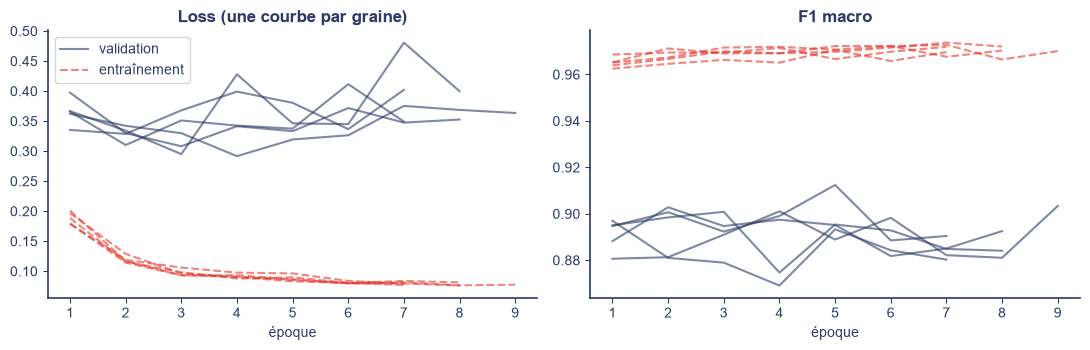

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, h in enumerate(hists):
    ax[0].plot(h["epoque"], h["val_loss"], color=BLEU, alpha=.6, label="validation" if i == 0 else None)
    ax[0].plot(h["epoque"], h["train_loss"], "--", color=ROUGE, alpha=.6, label="entraînement" if i == 0 else None)
    ax[1].plot(h["epoque"], h["val_f1"], color=BLEU, alpha=.6)
    ax[1].plot(h["epoque"], h["train_f1"], "--", color=ROUGE, alpha=.6)
ax[0].set_title("Loss (une courbe par graine)"); ax[1].set_title("F1 macro")
for a in ax: a.set_xlabel("époque")
ax[0].legend(); plt.tight_layout(); plt.show()

La loss d'entraînement descend régulièrement (≈ 0,08) et la F1 d'entraînement monte vers 0,97. La loss de validation atteint son minimum très tôt (époque 2 à 4, ≈ 0,3), puis fluctue entre 0,3 et 0,5 sans se stabiliser : l'arrêt précoce s'arrête donc après quelques époques seulement. La F1 de validation est bruitée (0,87 à 0,91) et reste loin de celle d'entraînement. Sur ces 5 volontaires, le CNN (≈ 0,896) fait moins bien que le MLP 1x64 (0,928) et que la régression logistique (0,919).

## Validation croisée par volontaires

Je reprends la validation croisée en 5 partitions regroupées par volontaire (`GroupKFold`) sur les 21 volontaires d'entraînement, avec 3 graines, pour comparer à la régression logistique et aux MLP sur le même type de mesure, et fixer le nombre d'époques du modèle final (médiane des meilleures époques).

In [ ]:
CV_FILE = "../results/v3_cnn_cv.csv"
if os.path.exists(CV_FILE):
    cv = pd.read_csv(CV_FILE); print("rechargé depuis", CV_FILE)
else:
    cv = []
    partitions = list(GroupKFold(n_splits=5).split(X_tr_all, y_tr_all, groups=s_tr_all))
    for fold, (itr, iva) in enumerate(partitions):
        Xa, Xv = standardiser(X_tr_all[itr], X_tr_all[iva])
        for seed in SEEDS[:3]:
            model, _, ep = entrainer(Xa, y_tr_all[itr], Xv, y_tr_all[iva], seed=seed)
            _, f1, _ = evaluer(model, Xv, y_tr_all[iva])
            cv.append({"partition": fold, "graine": seed, "f1": f1, "meilleure_epoque": ep})
        print(f"partition {fold + 1}/5 terminée")
    cv = pd.DataFrame(cv); cv.to_csv(CV_FILE, index=False)

par_partition = cv.groupby("partition")["f1"].mean()
EPOQUES_FINALES = int(round(cv["meilleure_epoque"].median()))
print("F1 par partition (moyenne sur les graines) :", par_partition.round(4).values)
print(f"CNN 1D : F1 validation croisée = {par_partition.mean():.4f} ± {par_partition.std():.4f} (écart-type entre partitions)")
print("Référence : régression logistique 0.9334 ± 0.0450 | MLP V2b 0.9306 ± 0.0556")
print("époques retenues pour le modèle final (médiane) :", EPOQUES_FINALES)

partition 1/5 terminée
partition 2/5 terminée
partition 3/5 terminée
partition 4/5 terminée
partition 5/5 terminée
F1 par partition (moyenne sur les graines) : [0.9243 0.867  0.9867 0.9561 0.9182]
CNN 1D : F1 validation croisée = 0.9304 ± 0.0448 (écart-type entre partitions)
Référence : régression logistique 0.9334 ± 0.0450 | MLP V2b 0.9306 ± 0.0556
époques retenues pour le modèle final (médiane) : 5


Non, mais il fait aussi bien : 0,930 ± 0,045, contre 0,931 ± 0,056 pour V2b et 0,933 ± 0,045 pour la régression logistique. Les écarts sont minuscules devant l'écart-type entre partitions. 

## Évaluation finale sur le test 

In [ ]:
FICHIER_TEST = "../results/test_final_v3.csv"
if os.path.exists(FICHIER_TEST):
    print(f"Note : {FICHIER_TEST} existe déjà, il est recalculé (graines fixées, résultats identiques).")
Xa, Xt = standardiser(X_tr_all, X_te)
res_test, preds = [], []
for seed in SEEDS:
    model, _, _ = entrainer(Xa, y_tr_all, seed=seed, epochs=EPOQUES_FINALES, arret_precoce=False)
    _, f1, pred = evaluer(model, Xt, y_te)
    res_test.append({"graine": seed, "f1": f1, "acc": accuracy_score(y_te, pred)}); preds.append(pred)
res_test = pd.DataFrame(res_test); res_test.to_csv(FICHIER_TEST, index=False)
print(f"CNN 1D : F1 test = {res_test['f1'].mean():.4f} ± {res_test['f1'].std():.4f} | accuracy = {res_test['acc'].mean():.4f} ± {res_test['acc'].std():.4f}")

CNN 1D : F1 test = 0.9296 ± 0.0095 | accuracy = 0.9284 ± 0.0095


,modèle,paramètres,F1 test (± std graines),F1 validation croisée
0,Régression logistique (561 variables),3372,0.9555,-
1,MLP V1 : 1x64 (561 variables),36358,0.9435 ± 0.0035,0.9252 ± 0.0552
2,"MLP V2b : 3x(256,128,64) (561 variables)",186310,0.9512 ± 0.0075,0.9306 ± 0.0556
3,CNN 1D (signaux bruts),24838,0.9296 ± 0.0095,0.9304 ± 0.0448


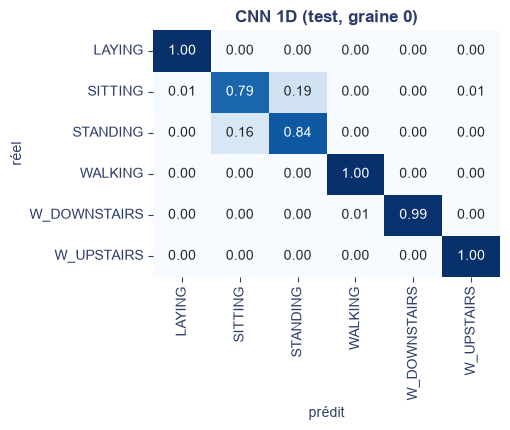

                    precision    recall  f1-score   support

            LAYING      0.993     0.998     0.995       537
           SITTING      0.820     0.790     0.805       491
          STANDING      0.825     0.840     0.832       532
           WALKING      0.994     1.000     0.997       496
WALKING_DOWNSTAIRS      1.000     0.990     0.995       420
  WALKING_UPSTAIRS      0.987     1.000     0.994       471

          accuracy                          0.935      2947
         macro avg      0.937     0.937     0.936      2947
      weighted avg      0.934     0.935     0.934      2947



In [ ]:
tab = pd.DataFrame([
    ["Régression logistique (561 variables)", 3372, "0.9555", "-"],
    ["MLP V1 : 1x64 (561 variables)", 36358, "0.9435 ± 0.0035", "0.9252 ± 0.0552"],
    ["MLP V2b : 3x(256,128,64) (561 variables)", 186310, "0.9512 ± 0.0075", "0.9306 ± 0.0556"],
    ["CNN 1D (signaux bruts)", n_params, f"{res_test['f1'].mean():.4f} ± {res_test['f1'].std():.4f}",
     f"{par_partition.mean():.4f} ± {par_partition.std():.4f}"],
], columns=["modèle", "paramètres", "F1 test (± std graines)", "F1 validation croisée"])
display(tab)

pred0 = preds[0]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
cm = confusion_matrix(y_te, pred0, normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax,
            xticklabels=[c.replace("WALKING_", "W_") for c in CLASSES], yticklabels=[c.replace("WALKING_", "W_") for c in CLASSES])
ax.set_xlabel("prédit"); ax.set_ylabel("réel"); ax.set_title("CNN 1D (test, graine 0)")
plt.tight_layout(); plt.show()
print(classification_report(y_te, pred0, target_names=CLASSES, digits=3))

Sur le test, le CNN (0,9296 ± 0,0095) reste 0,015 à 0,026 sous les MLP et la régression logistique, un écart supérieur à l'écart-type entre graines. Il classe presque parfaitement LAYING et les marches (rappel ≥ 0,99), mais confond plus SITTING et STANDING (F1 ≈ 0,81 et 0,83). Mon hypothèse est que les variables calculées à la main (angles par rapport à la gravité) distinguent directement ces postures, alors que le CNN doit retrouver cette légère inclinaison dans les signaux.

conclusion : 
Sans variable calculée à la main, le CNN 1D égale les MLP en validation croisée mais reste un peu en dessous sur le test, surtout à cause de SITTING/STANDING. Les signaux bruts suffisent pour les activités dynamiques, pas pour battre les variables expertes sur les postures. Limites : un seul réseau, peu de réglage, 21 volontaires.